# Week 10 project session: what the baseline did

**240MAR45 Reinforcement Learning in Robotics** | MSc Automatic Control and Robotics, UPC

**Where to run it.** On your laptop, in the project environment. Unpack this session's zip over your
project folder, run `jupyter lab` there, and open this notebook from `session/`. It needs the project
code, so it does not run in Colab.

You measured REINFORCE with and without a baseline on your own seeds. Here you read the same experiment
on twenty seeds, the reference runs shipped with this notebook. Everyone sees the same plots, so your
seed does not change any answer. Every cell finishes in seconds, and nothing trains.

## Objectives

1. Read off what a baseline changes in the gradient estimate and what it leaves alone.
2. Compare the three estimators on a problem with a known optimum and on the arm.
3. Say what a pair of seeds can and cannot show.
4. Place REINFORCE: what it has to wait for, and which Bellman object it uses.

## Session plan

This session is a practice round, so nothing counts. Later sessions run the same way and count for 5%.

| Part | Minutes |
|------|---------|
| Oral check, about 4 minutes per group. Other groups start this notebook | 28 |
| This notebook, Checkpoints 1 to 6 | 40 |
| Launch of Homework 2 | 5 |
| The quiz, on the university course page | 15 |

In [1]:
import inspect
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd() if (Path.cwd() / "harness").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from envs.scalar_lqr import riccati_solution
from harness.results import find_runs
from models.reinforce_baseline import baseline_loss

REFERENCE = ROOT / "reference" / "w10"
runs = find_runs(REFERENCE)
_, K_STAR = riccati_solution()
print(f"{len(runs)} reference runs loaded. K* = {K_STAR:.3f}")


def select(env, algo):
    return [run for run in runs if run["config"]["env"] == env and run["config"]["algo"] == algo]

82 reference runs loaded. K* = 1.007


## 1. A constant baseline, swept

Everything here is measured at one frozen policy on scalar LQR, so all differences come from the
estimator. A constant $b$ gives the estimator $\sum_t \gamma^t (G_t - b) \nabla\log\pi(u_t \mid x_t)$.
The left panel shows its relative variance as $b$ moves. The right panel shows how far its mean moves,
in standard errors.

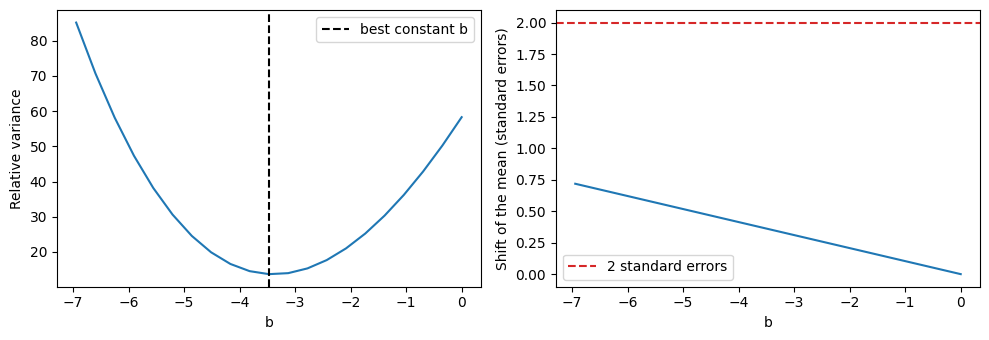

Relative variance at b = 0: 58.3. At the best b: 13.7.


In [2]:
lqr = np.load(REFERENCE / "gradient_variance_ScalarLQR-v0.npz")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(lqr["b_values"], lqr["b_variances"])
axes[0].axvline(float(lqr["b_best"]), color="k", linestyle="--", label="best constant b")
axes[0].set_xlabel("b")
axes[0].set_ylabel("Relative variance")
axes[0].legend()
axes[1].plot(lqr["b_values"], lqr["b_mean_shift"])
axes[1].axhline(2.0, color="C3", linestyle="--", label="2 standard errors")
axes[1].set_xlabel("b")
axes[1].set_ylabel("Shift of the mean (standard errors)")
axes[1].legend()
fig.tight_layout()
plt.show()
print(f"Relative variance at b = 0: {float(lqr['reward_to_go']):.1f}. At the best b: {float(lqr['b_variances'].min()):.1f}.")

### Checkpoint 1

As $b$ sweeps, which moves: the mean of the gradient estimate, its variance, or both?

## 2. Three estimators, two problems

The full return multiplies every score by the same $G_0$. Reward-to-go drops the rewards earned before
step $t$. The baseline subtracts a fitted $b_w(x_t)$, trained on other episodes of the same policy. The
last column of each pair counts the parameters whose mean differs from the full-return mean by more than
two standard errors, which is about 5% or less if the mean is unchanged.

In [3]:
arm = np.load(REFERENCE / "gradient_variance_PlanarArm-v0.npz")
print(f"{'estimator':<16}{'LQR':>10}{'shifted':>10}{'arm':>10}{'shifted':>10}")
for key, name in (("full_return", "full return"), ("reward_to_go", "reward-to-go"), ("baseline", "baseline")):
    print(f"{name:<16}{float(lqr[key]):>10.1f}{100 * float(lqr[key + '_shifted']):>9.0f}%"
          f"{float(arm[key]):>10.1f}{100 * float(arm[key + '_shifted']):>9.0f}%")
print(f"{'best constant':<16}{float(lqr['b_variances'].min()):>10.1f}{'':>10}{float(arm['b_variances'].min()):>10.1f}")

estimator              LQR   shifted       arm   shifted
full return          237.9        0%     460.6        0%
reward-to-go          58.3        0%     287.7        0%
baseline              10.3        0%      14.1        1%
best constant         13.7                27.6


### Checkpoint 2

On each problem, which step of the ladder buys the most: going from the full return to reward-to-go, or
adding the fitted baseline? Does a constant $b$ do as well as the fitted one?

## 3. Learning on scalar LQR

Twenty seeds of each algorithm with the same step budget, all starting from $K = 0.6$. The Riccati
equation gives the dashed line, so here the error can be read directly.

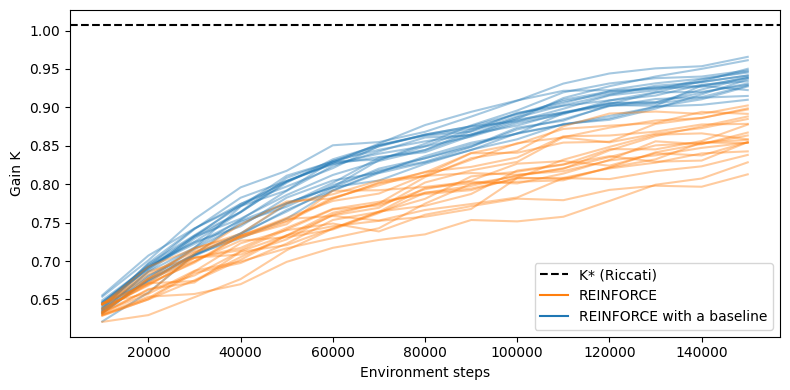

REINFORCE            final K = 0.865 +- 0.024, evaluation return -0.905
REINFORCE-BASELINE   final K = 0.938 +- 0.013, evaluation return -0.879
Riccati              K* = 1.007, evaluation return -0.868


In [4]:
gains = np.load(REFERENCE / "lqr_gains.npz")
fig, ax = plt.subplots(figsize=(8, 4))
final = {"REINFORCE": [], "REINFORCE-BASELINE": []}
for name in gains.files:
    if name == "steps":
        continue
    algo = "REINFORCE-BASELINE" if "BASELINE" in name else "REINFORCE"
    ax.plot(gains["steps"], gains[name], color="C1" if algo == "REINFORCE" else "C0", alpha=0.4)
    final[algo].append(gains[name][-1])
ax.axhline(K_STAR, color="k", linestyle="--", label="K* (Riccati)")
ax.plot([], [], color="C1", label="REINFORCE")
ax.plot([], [], color="C0", label="REINFORCE with a baseline")
ax.set_xlabel("Environment steps")
ax.set_ylabel("Gain K")
ax.legend()
fig.tight_layout()
plt.show()
for algo, values in final.items():
    returns = [run["eval_return"][-1] for run in select("ScalarLQR-v0", algo)]
    print(f"{algo:<20} final K = {np.mean(values):.3f} +- {np.std(values):.3f}, evaluation return {np.mean(returns):.3f}")
print(f"{'Riccati':<20} K* = {K_STAR:.3f}, evaluation return {select('ScalarLQR-v0', 'RICCATI')[0]['eval_return'][-1]:.3f}")

### Checkpoint 3

At this budget, which algorithm is closer to $K^\star$, and which has the smaller spread across seeds?
Has either one reached $K^\star$?

## 4. Learning on the arm, and what two seeds can show

The same two algorithms on the project arm, twenty seeds each. There is no Riccati line here, since no
formula gives the optimum for this task. The LQR controller, linearised at the target, is the dashed line.

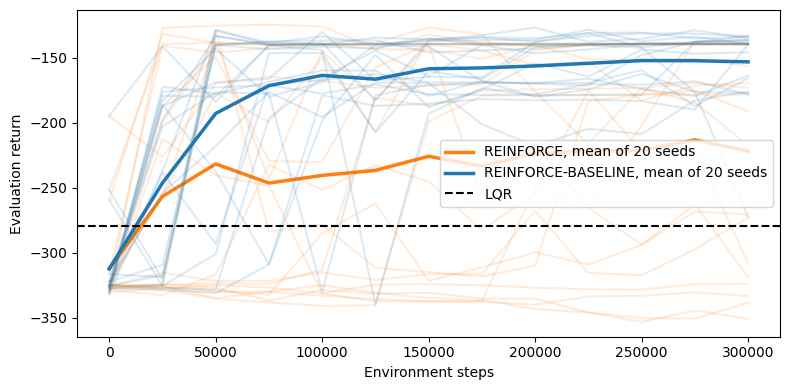

                        mean     std
REINFORCE             -221.9    79.9
REINFORCE-BASELINE    -153.3    31.3

Seeds where plain REINFORCE finished ahead: 4 of 20
  seed 14: REINFORCE -139.6, with baseline -272.6
  seed 18: REINFORCE -139.6, with baseline -140.1
  seed 19: REINFORCE -137.3, with baseline -166.0
  seed 7: REINFORCE -139.7, with baseline -146.0


In [5]:
seeds = {algo: {run["config"]["seed"]: run for run in select("PlanarArm-v0", algo)}
         for algo in ("REINFORCE", "REINFORCE-BASELINE")}
fig, ax = plt.subplots(figsize=(8, 4))
for algo, color in (("REINFORCE", "C1"), ("REINFORCE-BASELINE", "C0")):
    curves = np.array([run["eval_return"] for run in seeds[algo].values()])
    steps = next(iter(seeds[algo].values()))["eval_steps"]
    ax.plot(steps, curves.T, color=color, alpha=0.15)
    ax.plot(steps, curves.mean(axis=0), color=color, linewidth=2.5, label=f"{algo}, mean of {len(curves)} seeds")
ax.axhline(select("PlanarArm-v0", "LQR")[0]["eval_return"][-1], color="k", linestyle="--", label="LQR")
ax.set_xlabel("Environment steps")
ax.set_ylabel("Evaluation return")
ax.legend()
fig.tight_layout()
plt.show()

finals = {algo: {seed: run["eval_return"][-1] for seed, run in seeds[algo].items()} for algo in seeds}
wins = [seed for seed in finals["REINFORCE"] if finals["REINFORCE"][seed] > finals["REINFORCE-BASELINE"][seed]]
print(f"{'':<20}{'mean':>8}{'std':>8}")
for algo in finals:
    values = list(finals[algo].values())
    print(f"{algo:<20}{np.mean(values):>8.1f}{np.std(values):>8.1f}")
print(f"\nSeeds where plain REINFORCE finished ahead: {len(wins)} of {len(finals['REINFORCE'])}")
for seed in wins:
    print(f"  seed {seed}: REINFORCE {finals['REINFORCE'][seed]:.1f}, with baseline {finals['REINFORCE-BASELINE'][seed]:.1f}")

### Checkpoint 4

A group ran only seed 14 and reports that the baseline makes REINFORCE worse. What may they conclude from
that pair of runs, and what does the table above say instead?

In [6]:
# Your own runs next to the reference, if they are in runs/. No checkpoint depends on this cell.
yours = [run for run in find_runs(ROOT / "runs")] if (ROOT / "runs").exists() else []
yours = [run for run in yours if run["config"]["env"] == "PlanarArm-v0" and run["config"]["algo"] in seeds]
for run in yours:
    config = run["config"]
    print(f"{config['algo']:<20} {config['variation']:<10} seed {config['seed']:<4} final return {run['eval_return'][-1]:.1f}")
if not yours:
    print("No runs of yours found in runs/.")

REINFORCE            base       seed 3    final return -139.7
REINFORCE            lr3e4      seed 3    final return -284.7


## 5. What REINFORCE has to wait for

In [7]:
example = select("PlanarArm-v0", "REINFORCE")[0]
per_update = np.diff(example["train_steps"])
print(f"Environment steps between two ends of episode: {per_update.min():.0f}")
print(f"Over a budget of {example['eval_steps'][-1]:.0f} steps, that is {len(example['train_steps'])} policy updates.")

Environment steps between two ends of episode: 200
Over a budget of 300000 steps, that is 1500 policy updates.


### Checkpoint 5

How many environment steps does one policy update consume on the arm, and what forces REINFORCE to wait
that long?

## 6. Which Bellman object?

This is the regression your baseline is trained with.

In [8]:
print(inspect.getsource(baseline_loss))

def baseline_loss(returns, baseline_values):
    """Regression loss of the baseline on the return, averaged over the episode."""
    # BEGIN CORE c1_baseline_loss (≈1 line)
    # Goal: the mean squared error between b_w(x_t) and G_t.
    # Hint: Week 9 deck, line 7 is one stochastic gradient step on this quantity.
    return ((baseline_values - returns) ** 2).mean()
    # END CORE



### Checkpoint 6

The target of that regression is the observed return $G_t$. Does it read the value of the next state,
and which Bellman operator, if any, does the baseline solve for?

## 7. Analysis

These are broader than the checkpoints, and they are not quizzed.

1. Failure mode 2 is high variance in policy optimisation. Using the table in section 2, how much of it
   did the baseline remove on the arm? Do the learning curves in section 4 improve in the same proportion?
2. This week's deck lets the baseline read $V(x_{t+1})$. What would that change in Checkpoint 5, and what does
   it put at risk?

## Homework 2

Milestone 1 starts now: PPO and SAC, in `briefs/brief_w10_ppo_sac.md`. Before you leave, unpack the homework
zip and start one short run to check that it works:

```
python train.py --algo SAC --steps 1200 --eval-every 1200
```